     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.8/45.8 kB 2.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 61.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 34.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 36.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 918.2 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 18.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 60.5 MB/s eta 0:00:00
  Created wheel for nflows: filename=nflows-0.14-py3-none-any.whl size=53654 sha2

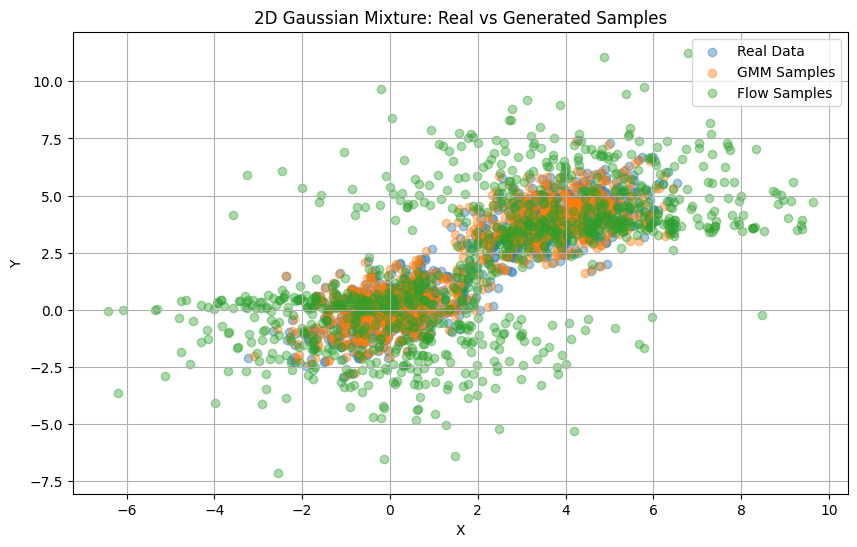

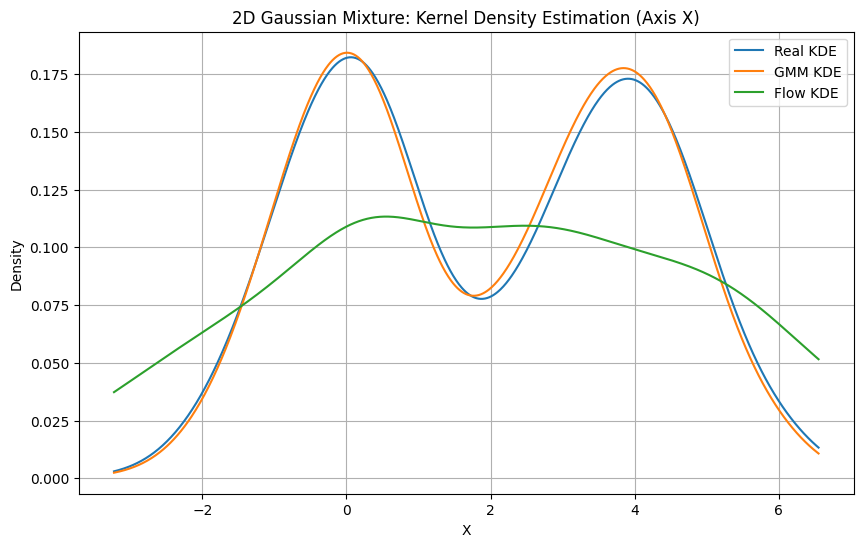

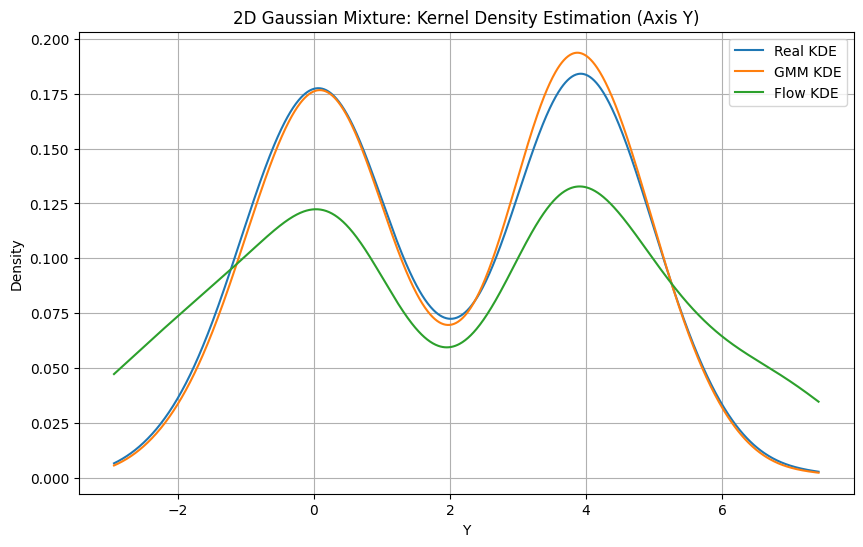


Model Comparison:
GMM Log-Likelihood: -1759.7963
Flow Log-Likelihood: -2388.0420
GMM KL Divergence: -0.0107
Flow KL Divergence: 10.8917
GMM has a higher log-likelihood.
GMM has a lower KL divergence (better fit).


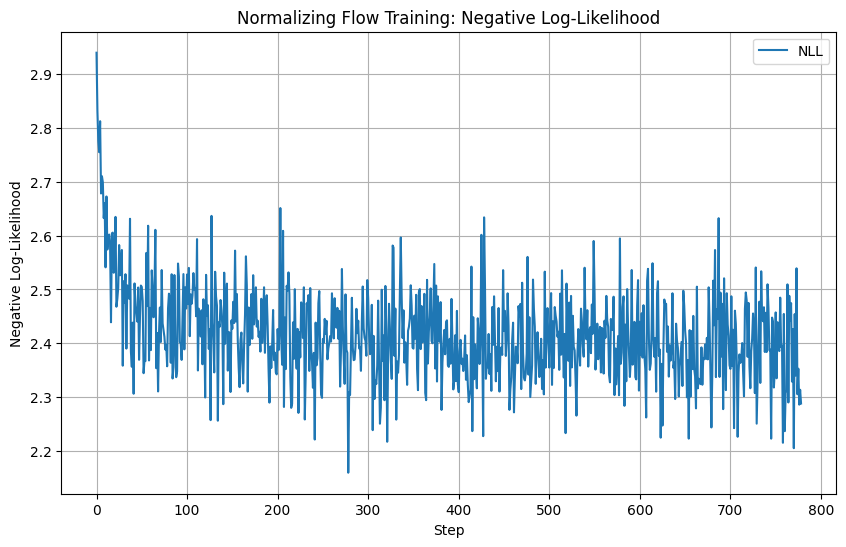

In [ ]:
!pip install nflows==0.14
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from nflows.flows.base import Flow
from nflows.transforms import CompositeTransform, ReversePermutation, PiecewiseRationalQuadraticCouplingTransform
from nflows.nn.nets import ResidualNet
from scipy.stats import gaussian_kde

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)

# 1. Generate 2D Gaussian Mixture Data
mean1 = [0, 0]
mean2 = [4, 4]
cov = [[1, 0.5], [0.5, 1]]
gauss1_2d = np.random.multivariate_normal(mean1, cov, 500)
gauss2_2d = np.random.multivariate_normal(mean2, cov, 500)
data_2d = np.vstack([gauss1_2d, gauss2_2d])  # Shape: (1000, 2)

# Normalize Data
scaler = StandardScaler()
data_2d_scaled = scaler.fit_transform(data_2d)
print("2D Gaussian data scaled mean:", data_2d_scaled.mean(axis=0))
print("2D Gaussian data scaled std:", data_2d_scaled.std(axis=0))

# 2. Fit Gaussian Mixture Model
gmm = GaussianMixture(n_components=2, random_state=42)
gmm.fit(data_2d_scaled)
gmm_log_likelihood = gmm.score(data_2d_scaled) * len(data_2d_scaled)  # Total log-likelihood

# 3. Custom Mixture of Gaussians for Flow Base Distribution
class CustomMixtureOfGaussians(torch.distributions.Distribution):
    arg_constraints = {}
    def __init__(self, means, variances, weights, input_dim=2, device='cpu'):
        super().__init__(validate_args=False)
        self.input_dim = input_dim
        self.distributions = [
            torch.distributions.MultivariateNormal(
                torch.tensor(m, dtype=torch.float32, device=device),
                torch.diag(torch.tensor(v, dtype=torch.float32, device=device))
            ) for m, v in zip(means, variances)
        ]
        self.weights = torch.tensor(weights, dtype=torch.float32, device=device)

    def log_prob(self, x, context=None):
        log_probs = torch.stack([d.log_prob(x) + torch.log(w) for d, w in zip(self.distributions, self.weights)], dim=0)
        return torch.logsumexp(log_probs, dim=0)

    def sample(self, sample_shape, context=None):
        if isinstance(sample_shape, int):
            sample_shape = (sample_shape,)
        z = torch.multinomial(self.weights, sample_shape[0], replacement=True)
        samples = torch.stack([self.distributions[i].sample(sample_shape) for i in range(len(self.distributions))])
        return samples[z, torch.arange(sample_shape[0])]

# 4. Create and Train Normalizing Flow
def create_flow(input_dim=2, hidden_features=128, num_layers=6):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    transforms = []
    masks = [torch.tensor([1, 0], dtype=torch.float32, device=device),
             torch.tensor([0, 1], dtype=torch.float32, device=device)] * (num_layers // 2)
    for mask in masks:
        transforms.append(ReversePermutation(features=input_dim))
        transforms.append(
            PiecewiseRationalQuadraticCouplingTransform(
                mask=mask,
                transform_net_create_fn=lambda in_features, out_features: ResidualNet(
                    in_features=in_features,
                    out_features=out_features,
                    hidden_features=hidden_features,
                    num_blocks=2,
                    activation=nn.ReLU()
                ),
                tails='linear',
                num_bins=4
            )
        )
    base_dist = CustomMixtureOfGaussians(
        means=[[-1.0, -1.0], [1.0, 1.0]],
        variances=[[1.0, 1.0], [1.0, 1.0]],
        weights=[0.5, 0.5],
        input_dim=input_dim,
        device=device
    )
    transform = CompositeTransform(transforms)
    flow = Flow(transform, base_dist).to(device)
    return flow

def train_flow(flow, data, steps=5000, lr=5e-4):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    flow = flow.to(device)
    optimizer = torch.optim.AdamW(flow.parameters(), lr=lr, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=2000, gamma=0.5)
    data_tensor = torch.tensor(data, dtype=torch.float32).to(device)
    losses = []
    batch_size = 64
    best_loss = float('inf')
    patience = 500
    steps_without_improvement = 0
    for step in range(steps):
        idx = np.random.choice(len(data), size=batch_size, replace=False)
        batch = data_tensor[idx]
        try:
            log_prob = flow.log_prob(batch)
            loss = -log_prob.mean()
            if not torch.isfinite(loss):
                print(f"Non-finite loss at step {step}")
                break
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(flow.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            losses.append(loss.item())
            if step % 500 == 0:
                print(f"Step {step} | NLL: {loss.item():.4f}")
            # Early stopping
            if loss.item() < best_loss:
                best_loss = loss.item()
                steps_without_improvement = 0
            else:
                steps_without_improvement += 1
                if steps_without_improvement >= patience:
                    print(f"Early stopping at step {step}")
                    break
        except Exception as e:
            print(f"Error at step {step}: {e}")
            raise
    flow_log_likelihood = flow.log_prob(data_tensor).sum().item()
    return flow, losses, flow_log_likelihood

# Train the flow
flow = create_flow(input_dim=2)
flow, losses, flow_log_likelihood = train_flow(flow, data_2d_scaled)

# 5. Evaluate Models
def compute_kl_divergence(real_data, generated_data):
    kl_scores = []
    for i in range(2):
        kde_real = gaussian_kde(real_data[:, i])
        kde_gen = gaussian_kde(generated_data[:, i])
        xs = np.linspace(
            min(real_data[:, i].min(), generated_data[:, i].min()),
            max(real_data[:, i].max(), generated_data[:, i].max()), 1000
        )
        p = np.clip(kde_real(xs), 1e-10, 1)
        q = np.clip(kde_gen(xs), 1e-10, 1)
        kl = np.sum(p * np.log(p / q))
        kl_scores.append(kl)
    return np.mean(kl_scores)

# Generate samples
gmm_samples_scaled = gmm.sample(len(data_2d_scaled))[0]
flow_samples_scaled = flow.sample(len(data_2d_scaled)).detach().cpu().numpy()

# Inverse transform to original scale
data_2d_original = scaler.inverse_transform(data_2d_scaled)
gmm_samples = scaler.inverse_transform(gmm_samples_scaled)
flow_samples = scaler.inverse_transform(flow_samples_scaled)

# Compute KL divergence
gmm_kl = compute_kl_divergence(data_2d_original, gmm_samples)
flow_kl = compute_kl_divergence(data_2d_original, flow_samples)

# 6. Visualization
plt.figure(figsize=(10, 6))
plt.scatter(data_2d_original[:, 0], data_2d_original[:, 1], alpha=0.4, label="Real Data")
plt.scatter(gmm_samples[:, 0], gmm_samples[:, 1], alpha=0.4, label="GMM Samples")
plt.scatter(flow_samples[:, 0], flow_samples[:, 1], alpha=0.4, label="Flow Samples")
plt.title("2D Gaussian Mixture: Real vs Generated Samples")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.grid(True)
plt.show()

for i, axis in enumerate(['X', 'Y']):
    plt.figure(figsize=(10, 6))
    kde_real = gaussian_kde(data_2d_original[:, i])
    kde_gmm = gaussian_kde(gmm_samples[:, i])
    kde_flow = gaussian_kde(flow_samples[:, i])
    xs = np.linspace(data_2d_original[:, i].min(), data_2d_original[:, i].max(), 1000)
    plt.plot(xs, kde_real(xs), label="Real KDE")
    plt.plot(xs, kde_gmm(xs), label="GMM KDE")
    plt.plot(xs, kde_flow(xs), label="Flow KDE")
    plt.title(f"2D Gaussian Mixture: Kernel Density Estimation (Axis {axis})")
    plt.xlabel(axis)
    plt.ylabel("Density")
    plt.legend()
    plt.grid(True)
    plt.show()

# 7. Comparison
print("\nModel Comparison:")
print(f"GMM Log-Likelihood: {gmm_log_likelihood:.4f}")
print(f"Flow Log-Likelihood: {flow_log_likelihood:.4f}")
print(f"GMM KL Divergence: {gmm_kl:.4f}")
print(f"Flow KL Divergence: {flow_kl:.4f}")

if flow_log_likelihood > gmm_log_likelihood:
    print("Normalizing Flow has a higher log-likelihood.")
else:
    print("GMM has a higher log-likelihood.")
if flow_kl < gmm_kl:
    print("Normalizing Flow has a lower KL divergence (better fit).")
else:
    print("GMM has a lower KL divergence (better fit).")

# Plot training loss
plt.figure(figsize=(10, 6))
plt.plot(losses, label="NLL")
plt.xlabel("Step")
plt.ylabel("Negative Log-Likelihood")
plt.title("Normalizing Flow Training: Negative Log-Likelihood")
plt.legend()
plt.grid(True)
plt.show()